# IE313 — Phân tích giá Airbnb tại 10 thành phố châu Âu

**Notebook trình bày toàn bộ đồ án — Hàn (A) và Huy (B).**

Mục tiêu: mô tả phân phối giá, so sánh thành phố/loại phòng/hai nhóm ngày,
khảo sát liên hệ với các thuộc tính và so sánh năm mô hình hồi quy trên cùng giao thức.
Phân tích giúp giải thích vì sao chỉ nhìn giá trung bình hoặc một hệ số tương quan là chưa đủ,
và kiểm tra mức sai số của mô hình trên các quan sát được giữ riêng.

Phạm vi là 20 CSV đã có trong repo; không bổ sung dữ liệu, mô hình cây hay ứng dụng ngoài kế hoạch.
Nguồn dữ liệu được README ghi là Kaggle / The Devastator. `realSum` giữ nguyên thang giá:
EUR **theo README**, kỳ giá chưa xác minh metadata gốc; không diễn giải thành giá mỗi đêm.
AI hỗ trợ viết code và bản thảo; hai thành viên cần hiểu, kiểm tra và khai báo công cụ thực tế.

**Cách sử dụng:** mở file này và chọn **Restart Kernel and Run All**. Code kiểm dữ liệu,
chia tập, EDA, xây dựng Pipeline, CV, dự đoán và phần dư đều nằm trong notebook;
không cần chạy các notebook khác hoặc import `src`. Các notebook 01–06 giữ lại để truy vết quá trình.
Khi demo, dùng các output đã chạy; không dành thời gian thuyết trình cho việc huấn luyện lại.

Trình tự: 1. Nguồn và kiểm dữ liệu → 2. EDA/Pearson/ANOVA → 3. Giao thức và hồi quy
→ 4. Đánh giá holdout → 5. Phần dư và kết luận → 6. Phân công và cách kiểm tra.

## 1. Nguồn, từ điển và hiện trạng dữ liệu — Hàn, Huy kiểm tra

Nạp từng file để kiểm số mẫu/schema, rồi thêm `city`, `day_type`, `source_file`, `source_row`.
Khóa file/dòng giúp quay lại dữ liệu gốc; `Unnamed: 0` và tọa độ không phải listing ID.
CSV gộp phải khớp dữ liệu nạp lại trước khi sử dụng split đã chốt.

In [47]:
from pathlib import Path
import hashlib, json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from scipy.stats import pearsonr, f_oneway
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import KFold, train_test_split, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures, StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'config/experiment_config.json').is_file()
             and (p / 'data/raw').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('Mở notebook từ thư mục repo hoặc notebooks; cần data/raw và config.')
FINAL_DIR = ROOT / 'outputs/final_notebook'
FINAL_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option('display.max_columns', 24)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
sns.set_theme(style='whitegrid', font='DejaVu Sans')
print('Repo:', ROOT)
print('Python:', sys.version.split()[0])

Repo: P:\CITD\HK3\Phân tích và trực quan dữ liệu\Đồ án môn học\Source
Python: 3.13.14


In [48]:
raw_files = sorted((ROOT / 'data/raw').glob('*.csv'))
assert len(raw_files) == 20
frames, inventory_rows = [], []
original_columns = pd.read_csv(raw_files[0], nrows=0).columns.tolist()
assert len(original_columns) == 20
for path in raw_files:
    part = pd.read_csv(path)
    assert part.columns.tolist() == original_columns, path.name
    city, day = path.stem.rsplit('_', 1)
    assert day in ['weekdays', 'weekends']
    inventory_rows.append({'file': path.name, 'n': len(part), 'columns': len(part.columns),
                           'missing_cells': int(part.isna().sum().sum())})
    part['city'], part['day_type'] = city, day
    part['source_file'], part['source_row'] = path.name, part['Unnamed: 0']
    frames.append(part)
df = pd.concat(frames, ignore_index=True)
inventory = pd.DataFrame(inventory_rows)
assert df.shape == (51707, 24)
assert df.city.nunique() == 10
assert df.groupby(['city', 'day_type']).size().shape[0] == 20
pd.testing.assert_frame_equal(df, pd.read_csv(ROOT / 'data/processed/airbnb_combined.csv'))
display(inventory)
print('Dữ liệu gộp:', df.shape)

,file,n,columns,missing_cells
0,amsterdam_weekdays.csv,1103,20,0
1,amsterdam_weekends.csv,977,20,0
2,athens_weekdays.csv,2653,20,0
3,athens_weekends.csv,2627,20,0
4,barcelona_weekdays.csv,1555,20,0
5,barcelona_weekends.csv,1278,20,0
6,berlin_weekdays.csv,1284,20,0
7,berlin_weekends.csv,1200,20,0
8,budapest_weekdays.csv,2074,20,0
9,budapest_weekends.csv,1948,20,0


Dữ liệu gộp: (51707, 24)


In [49]:
# Từ điển do nhóm đã review ở T03; nhúng trong notebook, không đọc bảng output cũ.
dictionary = pd.DataFrame([{'column_name': 'Unnamed: 0', 'data_type': 'int64', 'description_vi': 'Chỉ số dòng gốc trong từng tệp CSV riêng lẻ (reset về 0 ở mỗi tệp)', 'observed_range': 'Reset độc lập 0 – 5,378 trong từng file; không liên tục toàn cục', 'metadata_status': 'confirmed', 'redundancy_note': 'Không lặp', 'usage_note': '⛔ KHÔNG phải listing ID toàn cục. Không dùng để ghép cặp phòng giữa file hoặc làm predictor.'}, {'column_name': 'realSum', 'data_type': 'float64', 'description_vi': 'Tổng giá thuê trong kỳ lưu trú (theo README: đơn vị EUR, cho 2 người/2 đêm)', 'observed_range': '34.78 – 18,545.45 EUR (mean: 279.88, median: 211.34, skew: 21.42)', 'metadata_status': 'per_readme', 'redundancy_note': 'Không lặp', 'usage_note': 'Biến mục tiêu (target). Ghi "theo README", không tự quy đổi sang giá/đêm/người; chưa có metadata gốc xác minh.'}, {'column_name': 'room_type', 'data_type': 'str', 'description_vi': 'Loại phòng thuê trên Airbnb (Entire home/apt, Private room, Shared room)', 'observed_range': 'Entire home/apt (32,648), Private room (18,693), Shared room (366)', 'metadata_status': 'confirmed', 'redundancy_note': 'Biểu diễn chuẩn chính; chứa toàn bộ thông tin của room_shared và room_private', 'usage_note': 'Biểu diễn chính cho phân loại phòng; áp dụng One-Hot Encoding cho các mô hình hồi quy.'}, {'column_name': 'room_shared', 'data_type': 'bool', 'description_vi': 'Cờ logic đánh dấu phòng ở chia sẻ (True nếu là Shared room)', 'observed_range': 'False (51,341; 99.29%), True (366; 0.71%)', 'metadata_status': 'confirmed', 'redundancy_note': 'Suy ra trực tiếp từ room_type == "Shared room"', 'usage_note': 'Thuộc tính lặp. Loại khỏi tập biến dự báo (predictor) khi đã có room_type được mã hóa để tránh đa cộng tuyến hoàn hảo.'}, {'column_name': 'room_private', 'data_type': 'bool', 'description_vi': 'Cờ logic đánh dấu phòng riêng (True nếu là Private room)', 'observed_range': 'False (33,014; 63.85%), True (18,693; 36.15%)', 'metadata_status': 'confirmed', 'redundancy_note': 'Suy ra trực tiếp từ room_type == "Private room"', 'usage_note': 'Thuộc tính lặp. Loại khỏi tập biến dự báo (predictor) khi đã có room_type được mã hóa để tránh đa cộng tuyến hoàn hảo.'}, {'column_name': 'person_capacity', 'data_type': 'float64', 'description_vi': 'Sức chứa tối đa của chỗ nghỉ (số người/khách)', 'observed_range': '2 – 6 (số nguyên: [2, 3, 4, 5, 6])', 'metadata_status': 'per_readme', 'redundancy_note': 'Không lặp', 'usage_note': 'Biến số nguyên; r gộp toàn bộ ≈ 0.203 nhưng tại Amsterdam ≈ 0.528, Lisbon ≈ 0.573; giữ cho phân tích theo nhóm city.'}, {'column_name': 'host_is_superhost', 'data_type': 'bool', 'description_vi': 'Chủ nhà đạt danh hiệu Superhost trên nền tảng Airbnb', 'observed_range': 'False (38,475; 74.41%), True (13,232; 25.59%)', 'metadata_status': 'per_readme', 'redundancy_note': 'Không lặp', 'usage_note': 'Biến nhị phân boolean; chuyển thành cờ 0/1 khi đưa vào mô hình học máy.'}, {'column_name': 'multi', 'data_type': 'int64', 'description_vi': 'Cờ nhị phân (chưa có định nghĩa chính thức trong tài liệu đính kèm)', 'observed_range': '0 (36,642; 70.86%), 1 (15,065; 29.14%)', 'metadata_status': 'unclear', 'redundancy_note': 'Không lặp', 'usage_note': 'Metadata chưa rõ trong tài liệu gốc; không tự suy đoán quy mô hay ngưỡng kinh doanh.'}, {'column_name': 'biz', 'data_type': 'int64', 'description_vi': 'Cờ nhị phân (chưa có định nghĩa chính thức trong tài liệu đính kèm)', 'observed_range': '0 (33,599; 64.98%), 1 (18,108; 35.02%)', 'metadata_status': 'unclear', 'redundancy_note': 'Không lặp', 'usage_note': 'Metadata chưa rõ trong tài liệu gốc; không tự gán ý nghĩa khách công tác.'}, {'column_name': 'cleanliness_rating', 'data_type': 'float64', 'description_vi': 'Điểm số đánh giá mức độ vệ sinh sạch sẽ của chỗ nghỉ', 'observed_range': '2.0 – 10.0 (88.04% dòng >= 9.0; median: 10.0)', 'metadata_status': 'per_readme', 'redundancy_note': 'Không lặp', 'usage_note': 'Miền quan sát thực tế [2, 10]; phân biệt với thang đo chính thức của nền tảng; 88.04% bản ghi tập trung >= 9.'}, {'column_name': 'guest_satisfaction_overall', 'data_type': 'float64', 'description_vi': 'Điểm đánh giá mức độ hài lòng tổng thể từ khách lưu trú', 'observed_range': '20.0 – 100.0 (76.86% dòng >= 90.0; median: 95.0)', 'metadata_status': 'per_readme', 'redundancy_note': 'Không lặp', 'usage_note': 'Miền quan sát thực tế [20, 100]; 76.86% bản ghi tập trung >= 90; phân phối tập trung cao nên độ phân biệt có thể thấp.'}, {'column_name': 'bedrooms', 'data_type': 'int64', 'description_vi': 'Số lượng phòng ngủ của chỗ nghỉ', 'observed_range': '0 – 10 (số nguyên: [0, 1, 2, 3, 4, 5, 6, 8, 9, 10])', 'metadata_status': 'per_readme', 'redundancy_note': 'Không lặp', 'usage_note': 'Giá trị 0 là giá trị quan sát thực tế trong tập dữ liệu (hợp lệ, không phải ô thiếu); không tự suy diễn loại hình studio hoặc phòng mở khi metadata gốc chưa chứng minh.'}, {'column_name': 'dist', 'data_type': 'float64', 'description_vi': 'Khoảng cách từ chỗ nghỉ đến trung tâm thành phố (km theo README)', 'observed_range': '0.02 – 25.28 km (mean: 3.19 km, median: 2.61 km)', 'metadata_status': 'per_readme', 'redundancy_note': 'Không lặp', 'usage_note': 'Đơn vị km theo README; không quy đổi sang thời gian đi lại vì thiếu thông tin phương tiện di chuyển.'}, {'column_name': 'metro_dist', 'data_type': 'float64', 'description_vi': 'Khoảng cách từ chỗ nghỉ đến ga metro/tàu điện ngầm gần nhất (km theo README)', 'observed_range': '0.00 – 14.27 km (mean: 0.68 km, median: 0.41 km)', 'metadata_status': 'per_readme', 'redundancy_note': 'Không lặp', 'usage_note': 'Đơn vị km theo README; giá trị min thực tế là 0.0023 km (<0.01 km); hiển thị 0.00 km do làm tròn, không đồng nghĩa khoảng cách bằng 0 tuyệt đối hay sát cạnh ga.'}, {'column_name': 'attr_index', 'data_type': 'float64', 'description_vi': 'Chỉ số sức hấp dẫn du lịch khu vực (giá trị thô; công thức tính chưa có trong tài liệu)', 'observed_range': '15.15 – 4,513.56 (chỉ số thô)', 'metadata_status': 'unclear', 'redundancy_note': 'Có phiên bản chuẩn hóa tương ứng là attr_index_norm', 'usage_note': 'Chỉ số sức hấp dẫn du lịch thô; công thức tính chưa có trong tài liệu gốc.'}, {'column_name': 'attr_index_norm', 'data_type': 'float64', 'description_vi': 'Chỉ số sức hấp dẫn du lịch chuẩn hóa (README gốc bỏ sót cột này)', 'observed_range': '0.93 – 100.00 (chuẩn hóa thang 100, không phải [0, 1])', 'metadata_status': 'unclear', 'redundancy_note': 'Cặp với attr_index; README bỏ sót; cần lựa chọn một trong hai cho mô hình', 'usage_note': 'README gốc bỏ sót cột này; thang đo quan sát thực tế từ 0.93 đến 100.00.'}, {'column_name': 'rest_index', 'data_type': 'float64', 'description_vi': 'Chỉ số nhà hàng/ẩm thực khu vực (giá trị thô; công thức tính chưa có trong tài liệu)', 'observed_range': '19.58 – 6,696.16 (chỉ số thô)', 'metadata_status': 'unclear', 'redundancy_note': 'Có phiên bản chuẩn hóa tương ứng là rest_index_norm', 'usage_note': 'Chỉ số nhà hàng/ẩm thực thô; công thức tính chưa có trong tài liệu gốc.'}, {'column_name': 'rest_index_norm', 'data_type': 'float64', 'description_vi': 'Chỉ số nhà hàng/ẩm thực chuẩn hóa (README gốc bỏ sót cột này)', 'observed_range': '0.59 – 100.00 (chuẩn hóa thang 100, không phải [0, 1])', 'metadata_status': 'unclear', 'redundancy_note': 'Cặp với rest_index; README bỏ sót; cần lựa chọn một trong hai cho mô hình', 'usage_note': 'README gốc bỏ sót cột này; thang đo quan sát thực tế từ 0.59 đến 100.00.'}, {'column_name': 'lng', 'data_type': 'float64', 'description_vi': 'Kinh độ địa lý (Longitude theo tọa độ quan sát)', 'observed_range': '[-9.23, 23.79] (tọa độ các thành phố Châu Âu)', 'metadata_status': 'per_readme', 'redundancy_note': '21,582 bản ghi lặp tọa độ (city, lat, lng) — đặc tính lấy mẫu', 'usage_note': 'Hệ quy chiếu cụ thể chưa có trong tài liệu gốc; trực quan theo từng city; không diễn giải hệ số tọa độ gộp nhiều city là tác động địa lý phổ quát.'}, {'column_name': 'lat', 'data_type': 'float64', 'description_vi': 'Vĩ độ địa lý (Latitude theo tọa độ quan sát)', 'observed_range': '[37.95, 52.64] (tọa độ các thành phố Châu Âu)', 'metadata_status': 'per_readme', 'redundancy_note': '21,582 bản ghi lặp tọa độ (city, lat, lng) — đặc tính lấy mẫu', 'usage_note': 'Hệ quy chiếu cụ thể chưa có trong tài liệu gốc; trực quan theo từng city; không diễn giải hệ số tọa độ gộp nhiều city là tác động địa lý phổ quát.'}, {'column_name': 'city', 'data_type': 'str', 'description_vi': 'Tên thành phố Châu Âu, trích xuất từ tiền tố tên tệp CSV nguồn', 'observed_range': '10 thành phố: amsterdam, athens, barcelona, berlin, budapest, lisbon, london, paris, rome, vienna', 'metadata_status': 'created_by_team', 'redundancy_note': 'Không lặp', 'usage_note': 'Cột tạo mới bởi nhóm. Phân nhóm quan sát; One-Hot Encoding cho mô hình hồi quy.'}, {'column_name': 'day_type', 'data_type': 'str', 'description_vi': 'Phân loại thời điểm trong tuần (weekdays hoặc weekends), trích xuất từ tên tệp CSV nguồn', 'observed_range': 'weekdays (25,500; 49.32%), weekends (26,207; 50.68%)', 'metadata_status': 'created_by_team', 'redundancy_note': 'Không lặp', 'usage_note': 'Hai điều kiện khảo sát (ngày trong tuần vs cuối tuần) trên cùng thị trường lưu trú; không phải hai mẫu độc lập cũng không phải dữ liệu chuỗi thời gian.'}, {'column_name': 'source_file', 'data_type': 'str', 'description_vi': 'Tên tệp CSV gốc chứa bản ghi (ví dụ: amsterdam_weekdays.csv) — mã truy vết', 'observed_range': '20 tệp CSV nguồn (dạng <city>_<day_type>.csv)', 'metadata_status': 'created_by_team', 'redundancy_note': 'Không lặp', 'usage_note': 'Mã truy vết tệp nguồn; không dùng làm biến dự báo.'}, {'column_name': 'source_row', 'data_type': 'int64', 'description_vi': 'Chỉ số dòng gốc (giá trị Unnamed: 0) trong tệp CSV nguồn — mã truy vết', 'observed_range': '0 – 5,378 (chỉ số dòng gốc)', 'metadata_status': 'created_by_team', 'redundancy_note': 'Không lặp', 'usage_note': 'Mã truy vết dòng nguồn; không dùng làm biến dự báo.'}])
assert set(dictionary.column_name) == set(df.columns)
display(dictionary[['column_name', 'data_type', 'description_vi', 'metadata_status', 'usage_note']])

,column_name,data_type,description_vi,metadata_status,usage_note
0,Unnamed: 0,int64,Chỉ số dòng gốc trong từng tệp CSV riêng lẻ (r...,confirmed,⛔ KHÔNG phải listing ID toàn cục. Không dùng đ...
1,realSum,float64,Tổng giá thuê trong kỳ lưu trú (theo README: đ...,per_readme,"Biến mục tiêu (target). Ghi ""theo README"", khô..."
2,room_type,str,"Loại phòng thuê trên Airbnb (Entire home/apt, ...",confirmed,Biểu diễn chính cho phân loại phòng; áp dụng O...
3,room_shared,bool,Cờ logic đánh dấu phòng ở chia sẻ (True nếu là...,confirmed,Thuộc tính lặp. Loại khỏi tập biến dự báo (pre...
4,room_private,bool,Cờ logic đánh dấu phòng riêng (True nếu là Pri...,confirmed,Thuộc tính lặp. Loại khỏi tập biến dự báo (pre...
5,person_capacity,float64,Sức chứa tối đa của chỗ nghỉ (số người/khách),per_readme,Biến số nguyên; r gộp toàn bộ ≈ 0.203 nhưng tạ...
6,host_is_superhost,bool,Chủ nhà đạt danh hiệu Superhost trên nền tảng ...,per_readme,Biến nhị phân boolean; chuyển thành cờ 0/1 khi...
7,multi,int64,Cờ nhị phân (chưa có định nghĩa chính thức tro...,unclear,Metadata chưa rõ trong tài liệu gốc; không tự ...
8,biz,int64,Cờ nhị phân (chưa có định nghĩa chính thức tro...,unclear,Metadata chưa rõ trong tài liệu gốc; không tự ...
9,cleanliness_rating,float64,Điểm số đánh giá mức độ vệ sinh sạch sẽ của ch...,per_readme,"Miền quan sát thực tế [2, 10]; phân biệt với t..."


### 1.1. Vì sao cần kiểm dữ liệu trước khi phân tích?

Không có ô khuyết chưa đủ chứng minh dữ liệu đúng. Cần kiểm giá hữu hạn/dương,
miền thuộc tính, logic cờ loại phòng, khóa truy vết và tọa độ lặp. Không tạo giá trị khuyết giả
hoặc điền khuyết khi không cần. `bedrooms=0` là giá trị quan sát; chưa xác nhận là studio.
Ý nghĩa chi tiết `multi`, `biz`, các index và hệ tọa độ chưa được metadata gốc xác minh.

In [50]:
hidden_nulls = sum(int(df[c].astype(str).str.strip().str.lower().isin(
    ['', '?', '.', 'none', 'null', 'n/a', 'na', 'nan']).sum())
    for c in df.select_dtypes(include=['object', 'str']).columns)
checks = {
    'missing_cells': int(df.isna().sum().sum()),
    'hidden_null_markers': hidden_nulls,
    'nonfinite_numeric_cells': int((~np.isfinite(df.select_dtypes(include='number'))).sum().sum()),
    'nonpositive_prices': int((~df.realSum.gt(0)).sum()),
    'duplicate_trace_keys': int(df.duplicated(['source_file', 'source_row']).sum()),
    'invalid_room_type': int((~df.room_type.isin(['Entire home/apt', 'Private room', 'Shared room'])).sum()),
    'room_shared_mismatch': int((df.room_shared != df.room_type.eq('Shared room')).sum()),
    'room_private_mismatch': int((df.room_private != df.room_type.eq('Private room')).sum()),
    'invalid_boolean_flags': sum(int((~df[c].isin([True, False])).sum())
                                 for c in ['room_shared', 'room_private', 'host_is_superhost']),
    'invalid_capacity': int((~(df.person_capacity.ge(1) & df.person_capacity.mod(1).eq(0))).sum()),
    'invalid_bedrooms': int((~(df.bedrooms.ge(0) & df.bedrooms.mod(1).eq(0))).sum()),
    'negative_distances': int((df[['dist', 'metro_dist']] < 0).sum().sum()),
    'invalid_coordinate_range': int((~(df.lat.between(-90, 90) & df.lng.between(-180, 180))).sum()),
}
display(pd.Series(checks, name='Số vi phạm').to_frame())
assert not any(checks.values())
print('Dòng trùng toàn bộ 20 cột gốc:', df.duplicated(original_columns).sum())
print('Tọa độ city/lat/lng lặp sau lần đầu:', df.duplicated(['city', 'lat', 'lng']).sum())
print('Min metro_dist quan sát:', df.metro_dist.min())
display(df.select_dtypes(include='number').describe().T)

,Số vi phạm
missing_cells,0
hidden_null_markers,0
nonfinite_numeric_cells,0
nonpositive_prices,0
duplicate_trace_keys,0
invalid_room_type,0
room_shared_mismatch,0
room_private_mismatch,0
invalid_boolean_flags,0
invalid_capacity,0


Dòng trùng toàn bộ 20 cột gốc: 0
Tọa độ city/lat/lng lặp sau lần đầu: 21582
Min metro_dist quan sát: 0.0023010680119306


,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,"51,707.0000","1,620.5024","1,217.3804",0.0000,646.0000,"1,334.0000","2,382.0000","5,378.0000"
realSum,"51,707.0000",279.8796,327.9484,34.7793,148.7522,211.3431,319.6943,"18,545.4503"
person_capacity,"51,707.0000",3.1617,1.2985,2.0000,2.0000,3.0000,4.0000,6.0000
multi,"51,707.0000",0.2914,0.4544,0.0000,0.0000,0.0000,1.0000,1.0000
biz,"51,707.0000",0.3502,0.4770,0.0000,0.0000,0.0000,1.0000,1.0000
cleanliness_rating,"51,707.0000",9.3906,0.9549,2.0000,9.0000,10.0000,10.0000,10.0000
guest_satisfaction_overall,"51,707.0000",92.6282,8.9455,20.0000,90.0000,95.0000,99.0000,100.0000
bedrooms,"51,707.0000",1.1588,0.6274,0.0000,1.0000,1.0000,1.0000,10.0000
dist,"51,707.0000",3.1913,2.3938,0.0150,1.4531,2.6135,4.2631,25.2846
metro_dist,"51,707.0000",0.6815,0.8580,0.0023,0.2485,0.4133,0.7378,14.2736


### 1.2. Phân phối, IQR và quyết định giữ giá gốc

Mean, median, độ lệch chuẩn và skew mô tả các mặt khác nhau của phân phối. IQR gắn cờ
quan sát nằm ngoài `[Q1−1,5IQR; Q3+1,5IQR]`; kiểm cả gộp và từng city vì mặt bằng giá khác nhau.
Cờ IQR không chứng minh giá sai hay nhà sang trọng. Giữ nguyên các quan sát cho mọi mô hình;
không cắt đuôi test để giảm lỗi. Trục log chỉ giúp đọc hình, không biến đổi target hồi quy.

,scope,n,mean,median,std,skew,max,lower_fence,upper_fence,flagged
0,all_cities,51707,279.8796,211.3431,327.9484,21.4200,"18,545.4503",-107.6610,576.1075,3662
1,amsterdam,2080,573.1128,460.2442,430.6584,6.4413,"8,130.6681",-200.0973,"1,218.3641",105
2,athens,5280,151.7441,127.7154,265.8801,62.8250,"18,545.4503",-10.6625,280.8567,293
3,barcelona,2833,293.7537,208.2994,355.4679,12.4221,"6,943.7010",-92.6292,583.2383,227
4,berlin,2484,244.5838,191.1751,235.3293,12.8469,"5,857.4834",-55.2725,478.5220,165
5,budapest,4022,176.5135,152.9821,131.1448,13.3766,"3,751.2337",15.6272,307.9616,223
6,lisbon,5763,238.2105,225.3752,108.9731,1.9415,"1,681.0507",-29.0807,475.6098,192
7,london,9993,362.4693,261.2950,471.3573,16.2823,"15,499.8942",-233.3075,841.0358,531
8,paris,6688,392.5314,317.5972,330.9497,19.4118,"16,445.6147",-90.7587,793.7599,386
9,rome,9027,205.3919,182.5918,118.6181,5.8493,"2,418.3480",-15.1965,394.4077,433


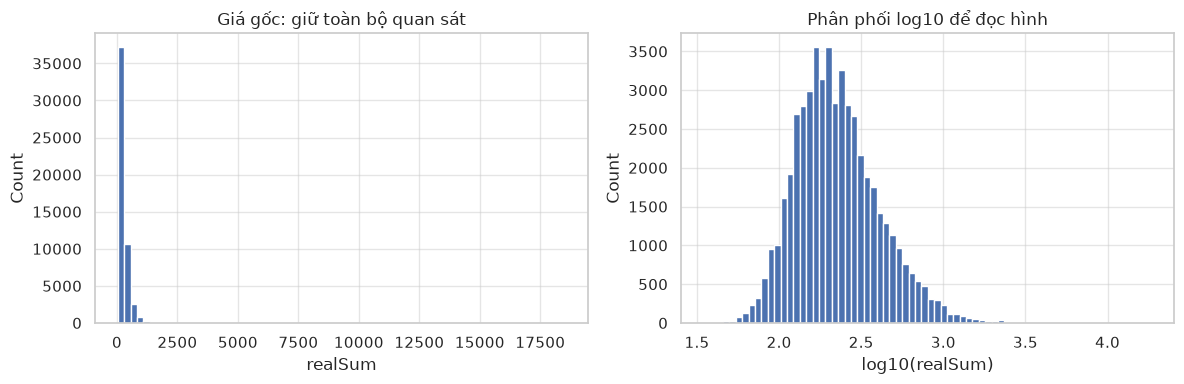

In [51]:
def iqr_row(frame):
    price = frame.realSum
    q1, q3 = price.quantile([.25, .75])
    lower, upper = q1 - 1.5*(q3-q1), q3 + 1.5*(q3-q1)
    return {'n': len(frame), 'mean': price.mean(), 'median': price.median(),
            'std': price.std(), 'skew': price.skew(), 'max': price.max(),
            'lower_fence': lower, 'upper_fence': upper,
            'flagged': int((price.lt(lower) | price.gt(upper)).sum())}
price_audit = pd.DataFrame([{'scope': 'all_cities', **iqr_row(df)}] +
                          [{'scope': city, **iqr_row(g)} for city, g in df.groupby('city')])
display(price_audit)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df.realSum, bins=70)
axes[0].set(title='Giá gốc: giữ toàn bộ quan sát', xlabel='realSum', ylabel='Count')
axes[1].hist(np.log10(df.realSum), bins=70)
axes[1].set(title='Phân phối log10 để đọc hình', xlabel='log10(realSum)', ylabel='Count')
plt.tight_layout(); plt.show()

### 1.3. Binning mô tả theo phần tiền xử lý đã có

Giữ các ngưỡng nhóm đã dùng trong Notebook 01: khoảng cách 0/1/3/5 km và giá 0/150/350/600.
Khoảng có cận trái đóng, cận phải mở. Đây là quy ước của nhóm để đọc bảng, chưa xác nhận
phân khúc thị trường. `price_tier` dẫn xuất trực tiếp từ target, chỉ dùng mô tả, không vào predictor.
Các cột này tạo trên bản sao riêng để dữ liệu cho mô hình vẫn đúng 24 cột.

In [52]:
descriptive = df.copy()
descriptive['dist_bin'] = pd.cut(descriptive.dist, [0, 1, 3, 5, np.inf],
                                labels=['[0,1)', '[1,3)', '[3,5)', '[5,+inf)'], right=False)
descriptive['price_tier'] = pd.cut(descriptive.realSum, [0, 150, 350, 600, np.inf],
                                  labels=['[0,150)', '[150,350)', '[350,600)', '[600,+inf)'], right=False)
assert not descriptive[['dist_bin', 'price_tier']].isna().any().any()
display(descriptive.groupby('dist_bin', observed=False).realSum.agg(n='size', mean='mean', median='median'))
display(pd.crosstab(descriptive.dist_bin, descriptive.price_tier, margins=True))
assert df.shape == (51707, 24)

,n,mean,median
dist_bin,,,
"[0,1)",7279,297.2791,228.8931
"[1,3)",21969,279.4675,210.1313
"[3,5)",13421,292.0496,218.8296
"[5,+inf)",9038,248.7961,188.1440


price_tier,"[0,150)","[150,350)","[350,600)","[600,+inf)",All
dist_bin,,,,,
"[0,1)",1340,4355,1031,553,7279
"[1,3)",6005,11428,3074,1462,21969
"[3,5)",2930,7322,2202,967,13421
"[5,+inf)",2946,4512,1237,343,9038
All,13221,27617,7544,3325,51707


**Điểm mạnh:** nhiều quan sát, schema đồng nhất, đủ hai nhóm ngày ở mỗi city, có khóa
file/dòng để kiểm lại và không cần imputation trong snapshot này.

**Điểm yếu:** mẫu loại phòng mất cân đối; giá lệch mạnh; thiếu kỳ thu thập và listing ID;
tọa độ lặp chưa rõ nguyên nhân; định nghĩa một số biến chưa chắc chắn.
Vì vậy cần báo cả n/median/IQR bên cạnh mean, so sánh trong city/room, giữ ngoại lệ và
phân tích lỗi theo nhóm. Kết quả áp dụng cho dữ liệu cung cấp, không đại diện chắc chắn toàn thị trường.

## 2. EDA và bằng chứng liên hệ — Huy, Hàn kiểm tra

**Q1:** giá và số mẫu khác nhau thế nào theo city/room? **Q2:** hai nhóm ngày có khác nhau,
và chênh lệch có đi kèm khác cơ cấu phòng? **Q3:** liên hệ tuyến tính của thuộc tính với giá
gộp và trong từng city? **Q4:** mean giá khác nhau theo nhóm trong ANOVA, với giới hạn gì?

Trước EDA, đọc allowlist và khóa split đã chốt để tách bảng full/train. EDA không dùng để
tự động chọn biến theo r/p trên toàn bộ dữ liệu.

In [53]:
config = json.loads((ROOT / 'config/experiment_config.json').read_text(encoding='utf-8'))
manifest = pd.read_csv(ROOT / config['split']['manifest'])
hash_now = hashlib.sha256((ROOT / config['data_file']).read_bytes().replace(b'\r\n', b'\n')).hexdigest()
assert hash_now == config['data_sha256']
pd.testing.assert_frame_equal(df[config['trace_keys']], manifest[config['trace_keys']])
expected_train, expected_test = train_test_split(np.arange(len(df)), test_size=.2, random_state=0)
expected_train = np.sort(expected_train)
assert np.array_equal(np.flatnonzero(manifest.split.eq('train')), expected_train)
assert np.array_equal(np.flatnonzero(manifest.split.eq('test')), np.sort(expected_test))
assert manifest.loc[manifest.split.eq('test'), 'cv_fold'].eq(-1).all()
train = df.loc[manifest.split.eq('train')].reset_index(drop=True)
test = df.loc[manifest.split.eq('test')].reset_index(drop=True)
train_folds = manifest.loc[manifest.split.eq('train'), 'cv_fold'].to_numpy()
cv = [(np.flatnonzero(train_folds != fold), np.flatnonzero(train_folds == fold)) for fold in range(5)]
for fold, (fit_idx, valid_idx) in enumerate(KFold(5, shuffle=True, random_state=0).split(train)):
    assert np.array_equal(cv[fold][0], fit_idx) and np.array_equal(cv[fold][1], valid_idx)
assert len(train) == 41365 and len(test) == 10342
assert set(train_folds) == set(range(5))
display(pd.DataFrame([{'fold': f, 'fit': len(a), 'validation': len(b)} for f, (a,b) in enumerate(cv)]))

,fold,fit,validation
0,0,33092,8273
1,1,33092,8273
2,2,33092,8273
3,3,33092,8273
4,4,33092,8273


In [54]:
def predictor_names(config):
    p = config['predictors']
    return p['numeric'] + p['categorical'] + p['boolean']

In [56]:
# Các bảng của notebook cuối ghi riêng; không ghi đè sản phẩm bàn giao cũ.
LIMIT = ('Mô tả liên hệ, không nhân quả; giá lệch phải/nhóm mất cân đối, '
         'độc lập mẫu chưa xác minh do tọa độ lặp; p nhỏ không đo độ lớn tác động.')
def save_table(frame, name, root=ROOT):
    path = FINAL_DIR / name
    frame.to_csv(path, index=False, encoding='utf-8-sig')
    return path

def price_summary(df, columns):
    table = df.groupby(columns, observed=True)['realSum'].agg(
        n='size', mean='mean', median='median', std='std',
        q1=lambda s: s.quantile(.25), q3=lambda s: s.quantile(.75)).reset_index()
    if len(columns) > 1:
        grid = pd.MultiIndex.from_product([sorted(df[c].unique()) for c in columns], names=columns)
        table = table.set_index(columns).reindex(grid).reset_index()
        table['n'] = table.n.fillna(0).astype(int)
    table['iqr'] = table.q3 - table.q1
    table['grouping'] = '+'.join(columns)
    table['availability'] = np.where(table.n.eq(0), 'no_observations', 'observed')
    return table


def build_eda_tables(df, root=ROOT):
    """Q1/Q2: bao gồm nhóm trống nhưng không gán giá 0 cho nhóm không có mẫu."""
    sets = [['city'], ['room_type'], ['city', 'day_type'], ['city', 'room_type'],
            ['city', 'room_type', 'day_type']]
    tables = [price_summary(df, cols) for cols in sets]
    summaries = pd.concat(tables, ignore_index=True)
    for _, g in summaries.groupby('grouping'):
        assert g.n.sum() == len(df)
        assert g.loc[g.n.eq(0), 'median'].isna().all()
    sampling = tables[-1].copy()
    sampling['share_of_city_day'] = sampling.n / sampling.groupby(['city', 'day_type']).n.transform('sum')
    pairs = sampling.pivot(index=['city', 'room_type'], columns='day_type', values=['n', 'mean', 'median'])
    pairs.columns = [metric + '_' + day for metric, day in pairs.columns]
    pairs = pairs.reset_index()
    pairs['median_difference_weekends_minus_weekdays'] = pairs.median_weekends - pairs.median_weekdays
    pairs['interpretation'] = 'Chênh hai nhóm quan sát; không ghép cặp cùng listing'
    # So sánh gộp city/day riêng, để thấy khác cơ cấu loại phòng.
    city_day = tables[2]
    city_pairs = city_day.pivot(index='city', columns='day_type', values=['n', 'mean', 'median'])
    city_pairs.columns = [metric + '_' + day for metric, day in city_pairs.columns]
    city_pairs = city_pairs.reset_index()
    city_pairs['median_difference_weekends_minus_weekdays'] = city_pairs.median_weekends - city_pairs.median_weekdays
    save_table(summaries, 'eda_group_summary.csv', root)
    save_table(sampling, 'eda_sampling_counts.csv', root)
    save_table(pairs, 'eda_day_comparison_by_room.csv', root)
    save_table(city_pairs, 'eda_day_comparison_by_city.csv', root)
    return summaries, sampling, city_pairs

In [57]:
group_summary, sampling, city_pairs = build_eda_tables(df)
display(group_summary.loc[group_summary.grouping.eq('city'), ['city', 'n', 'mean', 'median', 'iqr']])
display(group_summary.loc[group_summary.grouping.eq('room_type'), ['room_type', 'n', 'mean', 'median', 'iqr']])
display(city_pairs[['city', 'n_weekdays', 'n_weekends', 'median_weekdays', 'median_weekends',
                    'median_difference_weekends_minus_weekdays']])
display(pd.read_csv(FINAL_DIR / 'eda_day_comparison_by_room.csv'))

,city,n,mean,median,iqr
0,amsterdam,2080,573.1128,460.2442,354.6153
1,athens,5280,151.7441,127.7154,72.8798
2,barcelona,2833,293.7537,208.2994,168.9669
3,berlin,2484,244.5838,191.1751,133.4486
4,budapest,4022,176.5135,152.9821,73.0836
5,lisbon,5763,238.2105,225.3752,126.1726
6,london,9993,362.4693,261.2950,268.5858
7,paris,6688,392.5314,317.5972,221.1296
8,rome,9027,205.3919,182.5918,102.4010
9,vienna,3537,241.5825,208.4940,111.0254


,room_type,n,mean,median,iqr
10,Entire home/apt,32648,324.3152,248.4567,203.2275
11,Private room,18693,204.9402,166.3715,103.1782
12,Shared room,366,143.5662,124.4793,59.4382


,city,n_weekdays,n_weekends,median_weekdays,median_weekends,median_difference_weekends_minus_weekdays
0,amsterdam,"1,103.0000",977.0000,430.2486,491.6458,61.3971
1,athens,"2,653.0000","2,627.0000",127.7154,127.7154,0.0000
2,barcelona,"1,555.0000","1,278.0000",208.5321,204.6920,-3.8402
3,berlin,"1,284.0000","1,200.0000",187.7863,192.4605,4.6742
4,budapest,"2,074.0000","1,948.0000",147.4597,160.0320,12.5723
5,lisbon,"2,857.0000","2,906.0000",223.0300,227.7205,4.6904
6,london,"4,614.0000","5,379.0000",256.3560,268.1154,11.7594
7,paris,"3,130.0000","3,558.0000",318.5292,316.1991,-2.3301
8,rome,"4,492.0000","4,535.0000",179.7863,184.4622,4.6758
9,vienna,"1,738.0000","1,799.0000",204.5205,212.0001,7.4796


,city,room_type,n_weekdays,n_weekends,mean_weekdays,mean_weekends,median_weekdays,median_weekends,median_difference_weekends_minus_weekdays,interpretation
0,amsterdam,Entire home/apt,538.0000,588.0000,733.1791,736.0897,625.3369,614.4400,-10.8968,Chênh hai nhóm quan sát; không ghép cặp cùng l...
1,amsterdam,Private room,559.0000,385.0000,366.7647,407.7221,319.6401,350.3386,30.6986,Chênh hai nhóm quan sát; không ghép cặp cùng l...
2,amsterdam,Shared room,6.0000,4.0000,280.9739,280.7982,258.0086,229.7706,-28.2380,Chênh hai nhóm quan sát; không ghép cặp cùng l...
3,athens,Entire home/apt,"2,447.0000","2,425.0000",159.4463,150.6732,133.3396,133.3396,0.0000,Chênh hai nhóm quan sát; không ghép cặp cùng l...
4,athens,Private room,201.0000,196.0000,114.2659,111.3738,82.2534,78.1525,-4.1010,Chênh hai nhóm quan sát; không ghép cặp cùng l...
5,athens,Shared room,5.0000,6.0000,76.5355,80.3396,76.6293,83.4251,6.7959,Chênh hai nhóm quan sát; không ghép cặp cùng l...
6,barcelona,Entire home/apt,362.0000,180.0000,572.5601,745.0834,474.4339,532.0362,57.6023,Chênh hai nhóm quan sát; không ghép cặp cùng l...
7,barcelona,Private room,"1,185.0000","1,094.0000",202.7544,227.6689,185.2585,191.4260,6.1675,Chênh hai nhóm quan sát; không ghép cặp cùng l...
8,barcelona,Shared room,8.0000,4.0000,114.7974,142.6094,111.0154,145.2277,34.2123,Chênh hai nhóm quan sát; không ghép cặp cùng l...
9,berlin,Entire home/apt,474.0000,408.0000,351.9950,376.2302,289.8009,307.3292,17.5283,Chênh hai nhóm quan sát; không ghép cặp cùng l...


### 2.1. Biểu đồ nhóm và cơ cấu mẫu

Đọc count trước khi so sánh giá. Shared room có ít quan sát; tổ hợp không có mẫu có n=0,
giá giữ NaN thay vì điền 0. Chênh weekdays/weekends là hai tập quan sát, không ghép cặp cùng phòng.
Phân nhóm theo loại phòng giúp kiểm tra cơ cấu, chưa đủ để kết luận tác động nhân quả của cuối tuần.

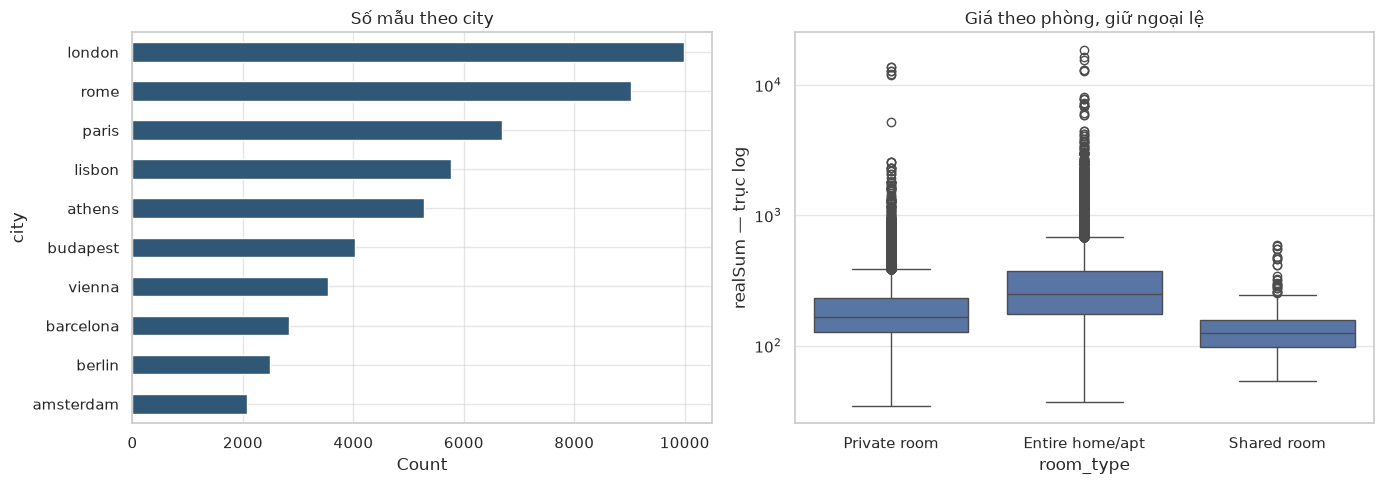

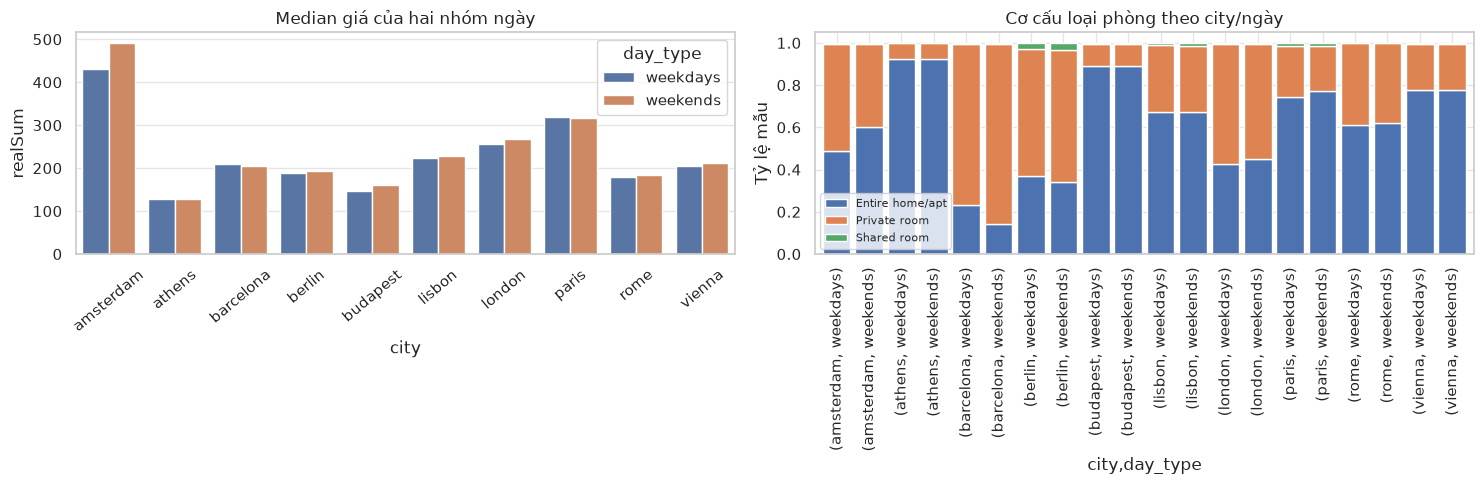

In [93]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
city_counts = df.city.value_counts().sort_values()
city_counts.plot.barh(ax=axes[0], color='#315776')
axes[0].set(title='Số mẫu theo city', xlabel='Count')
sns.boxplot(data=df, x='room_type', y='realSum', ax=axes[1], showfliers=True)
axes[1].set_yscale('log')
axes[1].set(title='Giá theo phòng, giữ ngoại lệ', ylabel='realSum — trục log')
plt.tight_layout(); plt.show()
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
city_day = group_summary.loc[group_summary.grouping.eq('city+day_type')]
sns.barplot(data=city_day, x='city', y='median', hue='day_type', errorbar=None, ax=axes[0])
axes[0].tick_params(axis='x', rotation=40)
axes[0].set(title='Median giá của hai nhóm ngày', ylabel='realSum')
shares = sampling.pivot(index=['city', 'day_type'], columns='room_type', values='share_of_city_day')
shares.plot.bar(stacked=True, ax=axes[1], width=.85)
axes[1].set(title='Cơ cấu loại phòng theo city/ngày', ylabel='Tỷ lệ mẫu')
axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

In [59]:
def p_fields(p):
    """SciPy có thể underflow p thành 0; không diễn giải là xác suất bằng 0."""
    underflow = p == 0.0
    return {'p_value': np.nan if underflow else p,
            'p_display': 'underflow_float64; not exact zero' if underflow else f'{p:.4e}',
            'p_underflow': underflow, 'p_lt_0_05': bool(p < .05)}


def build_evidence(df, train, config, root=ROOT):
    numeric = ['person_capacity', 'bedrooms', 'dist', 'metro_dist', 'cleanliness_rating',
               'guest_satisfaction_overall', 'attr_index', 'attr_index_norm',
               'rest_index', 'rest_index_norm', 'lng', 'lat']
    allowed = set(predictor_names(config))
    pearson_rows, anova_rows, group_rows = [], [], []
    for scope, data in [('full_descriptive', df), ('train_descriptive', train)]:
        # Bảng train chỉ là diễn giải kiểm tra; allowlist không được lọc bằng r/p này.
        contexts = [('all_cities', data)] + list(data.groupby('city', sort=True))
        for context, group in contexts:
            for feature in numeric:
                x, y = group[feature], group.realSum
                valid = x.notna() & y.notna()
                if valid.sum() < 3 or x[valid].nunique() < 2:
                    r, p = np.nan, np.nan
                else:
                    r, p = pearsonr(x[valid].to_numpy(), y[valid].to_numpy())
                row = {'scope': scope, 'context': context, 'feature': feature, 'n': int(valid.sum()),
                       'method': 'Pearson', 'r': r, 'abs_r_ge_0_3': bool(abs(r) >= .3),
                       'used_in_core_model': feature in allowed, 'limitations': LIMIT}
                row.update(p_fields(p)); pearson_rows.append(row)
        for feature, context, group in [('city', 'all_cities', data),
                                         ('room_type', 'all_cities', data)] + [
                                         ('room_type', city, g) for city, g in data.groupby('city')]:
            groups = [(label, g.realSum.to_numpy()) for label, g in group.groupby(feature, observed=True)]
            arrays = [a for _, a in groups]
            variances = [np.var(a, ddof=1) for a in arrays if len(a) > 1]
            if len(arrays) >= 2 and all(len(a) >= 2 for a in arrays):
                f, p = f_oneway(*arrays)
            else:
                f, p = np.nan, np.nan
            row = {'scope': scope, 'context': context, 'feature': feature, 'method': 'One-way ANOVA',
                   'n': len(group), 'n_groups': len(groups), 'min_group_n': min(map(len, arrays)),
                   'f': f, 'variance_ratio_max_min': max(variances)/min(variances) if variances and min(variances)>0 else np.nan,
                   'used_in_core_model': feature in allowed, 'limitations': LIMIT}
            row.update(p_fields(p)); anova_rows.append(row)
            for label, a in groups:
                group_rows.append({'scope': scope, 'context': context, 'feature': feature,
                                   'group': label, 'n': len(a), 'mean': np.mean(a), 'median': np.median(a),
                                   'std': np.std(a, ddof=1) if len(a)>1 else np.nan})
    pearson = pd.DataFrame(pearson_rows)
    anova = pd.DataFrame(anova_rows)
    evidence = pd.concat([pearson, anova], ignore_index=True)
    evidence['decision'] = np.where(evidence.used_in_core_model, 'semantic_core_candidate', 'descriptive_only_excluded_core')
    evidence['decision_basis'] = 'Allowlist định trước theo ý nghĩa/metadata; r/p/F là mô tả, không tự động chọn theo y'
    save_table(pearson, 'pearson_price_evidence.csv', root)
    save_table(anova, 'anova_price_evidence.csv', root)
    save_table(pd.DataFrame(group_rows), 'anova_group_details.csv', root)
    save_table(evidence, 'feature_evidence.csv', root)
    corr = df[numeric + ['realSum']].corr()
    save_table(corr.reset_index(names='feature'), 'eda_correlation_matrix.csv', root)
    return pearson, anova, corr

,feature,n,r,p_display,used_in_core_model
0,person_capacity,51707,0.2031,underflow_float64; not exact zero,True
1,bedrooms,51707,0.2217,underflow_float64; not exact zero,True
2,dist,51707,-0.0447,2.5631e-24,True
3,metro_dist,51707,-0.0610,7.3765e-44,True
4,cleanliness_rating,51707,-0.0061,1.6668e-01,True
5,guest_satisfaction_overall,51707,-0.0019,6.6778e-01,True
6,attr_index,51707,0.1782,underflow_float64; not exact zero,False
7,attr_index_norm,51707,0.2924,underflow_float64; not exact zero,False
8,rest_index,51707,0.1347,5.7638e-208,False
9,rest_index_norm,51707,0.1441,6.5072e-238,False


,context,n,r,p_display
0,all_cities,51707,0.2031,underflow_float64; not exact zero
12,amsterdam,2080,0.5276,2.0514e-149
24,athens,5280,0.0915,2.7682e-11
36,barcelona,2833,0.3747,4.0989e-95
48,berlin,2484,0.3123,2.5747e-57
60,budapest,4022,0.2350,1.3556e-51
72,lisbon,5763,0.5729,underflow_float64; not exact zero
84,london,9993,0.3524,3.9353e-290
96,paris,6688,0.3956,1.8522e-249
108,rome,9027,0.4039,underflow_float64; not exact zero


,feature,n,min_group_n,f,p_display,variance_ratio_max_min
0,city,51707,2080,605.7186,underflow_float64; not exact zero,18.7095
1,room_type,51707,366,846.1375,underflow_float64; not exact zero,19.6865


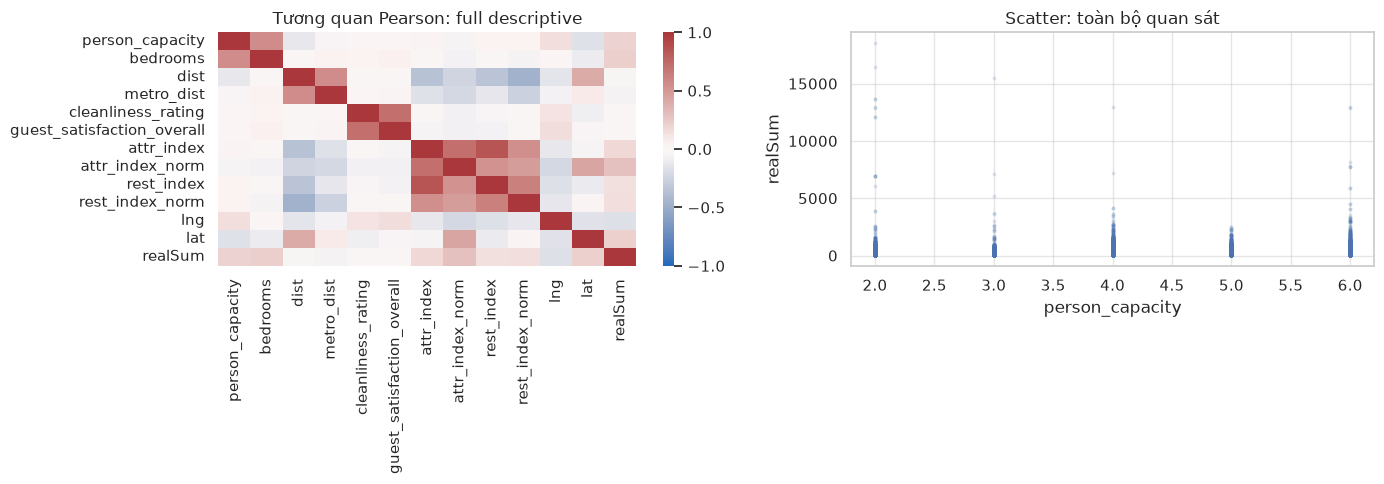

In [60]:
pearson, anova, corr = build_evidence(df, train, config)
display(pearson.loc[(pearson.scope == 'full_descriptive') & (pearson.context == 'all_cities'),
                    ['feature', 'n', 'r', 'p_display', 'used_in_core_model']])
display(pearson.loc[(pearson.scope == 'full_descriptive') & (pearson.feature == 'person_capacity'),
                    ['context', 'n', 'r', 'p_display']])
display(anova.loc[(anova.scope == 'full_descriptive') & (anova.context == 'all_cities'),
                  ['feature', 'n', 'min_group_n', 'f', 'p_display', 'variance_ratio_max_min']])
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(corr, cmap='vlag', center=0, vmin=-1, vmax=1, ax=axes[0])
axes[0].set(title='Tương quan Pearson: full descriptive')
axes[1].scatter(df.person_capacity, df.realSum, s=4, alpha=.12)
axes[1].set(xlabel='person_capacity', ylabel='realSum', title='Scatter: toàn bộ quan sát')
plt.tight_layout(); plt.show()

### 2.2. Diễn giải Pearson/ANOVA và vì sao không lọc biến máy móc

Pearson đo liên hệ tuyến tính, nhạy với giá lớn và việc gộp city; r gộp nhỏ không bác bỏ
liên hệ trong từng city. ANOVA kiểm khác biệt mean giữa nhóm, không chứng minh mọi cặp khác
nhau hay mức tác động lớn. Giá lệch, nhóm mất cân đối và tính độc lập chưa xác minh làm
giới hạn giả định kiểm định. p underflow được ghi rõ, không gọi xác suất chính xác bằng 0.

Giữ predictor theo ý nghĩa/metadata đã chốt; r/p/F là bằng chứng mô tả. Không áp ngưỡng
Pearson của bài tập giá xe để loại hết biến Airbnb. Tất cả bảng full/train được phân biệt.

## 3. Giao thức và năm mô hình hồi quy — Hàn M0–M2, Huy M3–M4

**41.365 train / 10.342 test**, seed 0, 5-fold CV trong train. Mỗi fold gồm 33.092 fit và
8.273 validation. So sánh cùng fold, target giá gốc và MSE CV trung bình.
Scaler/OneHot/Polynomial nằm trong Pipeline, được fit trong từng fold.

10 predictor gốc: sáu biến số, ba biến phân loại, một cờ Superhost. Không dùng ID,
log giá/price tier, cờ room trùng thông tin, metadata chưa chắc chắn hoặc tọa độ trong core.
`dist_bin` là dẫn xuất từ khoảng cách, được bỏ do dư thừa theo giao thức, không phải biến dẫn xuất từ target.

M0: trung bình train (mốc so sánh); M1: tuyến tính sức chứa; M2: tuyến tính đa biến;
M3: đa thức bậc 2/3 chỉ trên capacity/bedrooms/dist; M4: Ridge với bảy alpha đã định.
M2/M4 có 19 cột sau encoding; M3 bậc 2 có 25, bậc 3 có 35 cột. Chọn biến thể và mô hình
bằng CV trước phần đánh giá test. Test đã được mở ở T10 trước đây; lượt này tái lập giao thức
đã chốt, không giả vờ có một holdout mới chưa từng xem.

In [61]:
def build_pipeline(model_id, config, degree=None, alpha=None):
    """A dùng M0/M1/M2, B dùng M3/M4; tất cả fit preprocessing trong CV."""
    numeric = config['predictors']['numeric']
    if model_id == 'M0':
        return Pipeline([('model', DummyRegressor(strategy='mean'))])
    if model_id == 'M1':
        pre = ColumnTransformer([('slr', 'passthrough', [config['slr_feature']])], remainder='drop')
        return Pipeline([('preprocess', pre), ('model', LinearRegression())])
    parts = []
    if model_id == 'M3':
        poly = config['polynomial_features']
        parts.append(('polynomial', Pipeline([
            ('expand', PolynomialFeatures(degree=degree, include_bias=False)),
            ('scale', StandardScaler())]), poly))
        numeric = [c for c in numeric if c not in poly]
    parts += [('numeric', StandardScaler(), numeric),
              ('categorical', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False),
               config['predictors']['categorical']),
              ('boolean', 'passthrough', config['predictors']['boolean'])]
    pre = ColumnTransformer(parts, remainder='drop')
    estimator = Ridge(alpha=alpha) if model_id == 'M4' else LinearRegression()
    return Pipeline([('preprocess', pre), ('model', estimator)])


def evaluate_cv(pipeline, train, cv, config, model_id, variant):
    """Không nhận test; RMSE trung bình fold khác căn của MSE trung bình fold."""
    scores = cross_validate(pipeline, train[predictor_names(config)], train[config['target']], cv=cv,
                            scoring={'mse': 'neg_mean_squared_error', 'mae': 'neg_mean_absolute_error',
                                     'r2': 'r2'}, return_train_score=True, n_jobs=1, error_score='raise')
    rows = []
    for fold in range(len(cv)):
        row = {'model_id': model_id, 'variant': variant, 'fold': fold,
               'n_fold_train': len(cv[fold][0]), 'n_fold_validation': len(cv[fold][1]),
               'protocol_id': config['protocol_id']}
        for part, prefix in [('test', 'validation'), ('train', 'train')]:
            row[prefix + '_mse'] = -scores[part + '_mse'][fold]
            row[prefix + '_rmse'] = np.sqrt(row[prefix + '_mse'])
            row[prefix + '_mae'] = -scores[part + '_mae'][fold]
            row[prefix + '_r2'] = scores[part + '_r2'][fold]
        rows.append(row)
    folds = pd.DataFrame(rows)
    summary = {'model_id': model_id, 'variant': variant, 'protocol_id': config['protocol_id'],
               'n_train': len(train), 'n_folds': len(cv)}
    for part, prefix in [('validation', 'cv'), ('train', 'fold_train')]:
        for metric in ['mse', 'rmse', 'mae', 'r2']:
            summary[prefix + '_' + metric + '_mean'] = folds[part + '_' + metric].mean()
            summary[prefix + '_' + metric + '_std'] = folds[part + '_' + metric].std(ddof=1)
    return summary, folds

In [62]:
X_train, y_train = train[predictor_names(config)], train[config['target']]
specs = [('M0', 'mean_baseline', {}), ('M1', 'slr_person_capacity', {}), ('M2', 'mlr_core', {})]
specs += [('M3', f'degree_{d}', {'degree': d}) for d in config['polynomial_degrees']]
specs += [('M4', f'alpha_{a:g}', {'alpha': a}) for a in config['ridge_alphas']]
cv_rows, fold_rows = [], []
for model_id, variant, params in specs:
    pipeline = build_pipeline(model_id, config, **params)
    summary, detail = evaluate_cv(pipeline, train, cv, config, model_id, variant)
    cv_rows.append({**summary, **params})
    fold_rows.append(detail)
    print(model_id, variant, 'CV MSE =', round(summary['cv_mse_mean'], 2))
cv_summary = pd.DataFrame(cv_rows)
cv_folds = pd.concat(fold_rows, ignore_index=True)
assert len(cv_summary) == 12 and len(cv_folds) == 60
display(cv_summary[['model_id', 'variant', 'fold_train_mse_mean', 'cv_mse_mean',
                    'cv_mse_std', 'cv_rmse_mean', 'cv_mae_mean', 'cv_r2_mean']])
save_table(cv_summary, 'all_configurations_cv.csv')
save_table(cv_folds, 'all_configurations_folds.csv')

M0 mean_baseline CV MSE = 104402.75
M1 slr_person_capacity CV MSE = 99919.96
M2 mlr_core CV MSE = 79988.15
M3 degree_2 CV MSE = 79616.75
M3 degree_3 CV MSE = 79228.0
M4 alpha_0.001 CV MSE = 79988.15
M4 alpha_0.01 CV MSE = 79988.15
M4 alpha_0.1 CV MSE = 79988.15
M4 alpha_1 CV MSE = 79988.33
M4 alpha_10 CV MSE = 80006.64
M4 alpha_100 CV MSE = 80725.81
M4 alpha_1000 CV MSE = 84147.42


,model_id,variant,fold_train_mse_mean,cv_mse_mean,cv_mse_std,cv_rmse_mean,cv_mae_mean,cv_r2_mean
0,M0,mean_baseline,"104,401.9283","104,402.7536","18,227.9902",322.0892,146.4071,-0.0000
1,M1,slr_person_capacity,"99,918.5690","99,919.9617","18,372.5085",314.9863,139.1291,0.0443
2,M2,mlr_core,"79,912.3698","79,988.1486","18,800.2106",281.1684,104.3512,0.2409
3,M3,degree_2,"79,455.2486","79,616.7538","18,821.2735",280.4955,103.2599,0.2446
4,M3,degree_3,"78,883.6584","79,227.9979","18,787.1387",279.8001,102.9403,0.2483
5,M4,alpha_0.001,"79,912.3698","79,988.1485","18,800.2109",281.1684,104.3512,0.2409
6,M4,alpha_0.01,"79,912.3698","79,988.1483","18,800.2133",281.1684,104.3509,0.2409
7,M4,alpha_0.1,"79,912.3719","79,988.1477","18,800.2368",281.1684,104.3486,0.2409
8,M4,alpha_1,"79,912.5822","79,988.3306","18,800.4737",281.1687,104.3256,0.2409
9,M4,alpha_10,"79,931.1348","80,006.6364","18,802.9823",281.2012,104.1329,0.2407


WindowsPath('P:/CITD/HK3/Phân tích và trực quan dữ liệu/Đồ án môn học/Source/outputs/final_notebook/all_configurations_folds.csv')

`cross_validate` gọi điểm validation là `test_*`; hàm đã đổi tên để không nhầm holdout.
MSE/MAE scorer có dấu âm được đổi về dương, R² giữ nguyên. Mean RMSE của folds không nhất
thiết bằng căn mean MSE. Chênh train/CV phản ánh sai số trong cấu hình này; chưa đủ để
tuyên bố chắc chắn mô hình không overfit.

In [63]:
selected_cv = cv_summary.loc[cv_summary.groupby('model_id').cv_mse_mean.idxmin()].copy()
winner_id = selected_cv.loc[selected_cv.cv_mse_mean.idxmin(), 'model_id']
selected_cv['selected_winning_model'] = selected_cv.model_id.eq(winner_id)
models = {}
for row in selected_cv.itertuples():
    params = {'degree': int(row.degree)} if row.model_id == 'M3' else (
             {'alpha': float(row.alpha)} if row.model_id == 'M4' else {})
    model = build_pipeline(row.model_id, config, **params)
    model.fit(X_train, y_train)  # Refit chỉ toàn bộ train sau chọn CV.
    models[row.model_id] = model
display(selected_cv[['model_id', 'variant', 'cv_mse_mean', 'selected_winning_model']])
print('Mô hình khóa bằng CV:', winner_id)
assert winner_id == 'M3'
assert int(selected_cv.loc[selected_cv.model_id.eq('M3'), 'degree'].iloc[0]) == 3
assert float(selected_cv.loc[selected_cv.model_id.eq('M4'), 'alpha'].iloc[0]) == .1

,model_id,variant,cv_mse_mean,selected_winning_model
0,M0,mean_baseline,"104,402.7536",False
1,M1,slr_person_capacity,"99,919.9617",False
2,M2,mlr_core,"79,988.1486",False
4,M3,degree_3,"79,227.9979",True
7,M4,alpha_0.1,"79,988.1477",False


Mô hình khóa bằng CV: M3


### 3.1. Phương trình và hệ số tuyến tính để giải thích code

M1 dùng sức chứa trên đơn vị gốc. Intercept là giá trị của phương trình tại capacity=0,
không gọi là giá sàn. M2 chuẩn hóa biến số: hệ số tương ứng tăng một độ lệch chuẩn khi
giữ các predictor khác cố định; chia hệ số cho scale để đọc theo đơn vị gốc.
Dummy so với nhóm tham chiếu được in ra. Hệ số là liên hệ trong mô hình, không chứng minh nhân quả.

In [64]:
m1 = models['M1'].named_steps['model']
print(f'M1: realSum_hat = {m1.intercept_:.4f} + {m1.coef_[0]:.4f} * person_capacity')
m2 = models['M2']
names = m2.named_steps['preprocess'].get_feature_names_out()
coefficients = pd.DataFrame({'feature': names, 'coefficient': m2.named_steps['model'].coef_})
coefficients['coefficient_per_original_unit'] = np.nan
scaler = m2.named_steps['preprocess'].named_transformers_['numeric']
coefficients.loc[coefficients.feature.str.startswith('numeric__'), 'coefficient_per_original_unit'] = (
    coefficients.loc[coefficients.feature.str.startswith('numeric__'), 'coefficient'].to_numpy() / scaler.scale_)
print('M2 intercept trên biểu diễn đã biến đổi:', m2.named_steps['model'].intercept_)
encoder = m2.named_steps['preprocess'].named_transformers_['categorical']
print('Nhóm tham chiếu:', {name: categories[0] for name, categories in
                            zip(config['predictors']['categorical'], encoder.categories_)})
display(coefficients)
for model_id in ['M2', 'M3', 'M4']:
    print(model_id, 'số cột sau encoding:', models[model_id].named_steps['preprocess'].transform(X_train.iloc[:1]).shape[1])

M1: realSum_hat = 117.2114 + 51.5181 * person_capacity
M2 intercept trên biểu diễn đã biến đổi: 620.9026366587732
Nhóm tham chiếu: {'city': 'amsterdam', 'day_type': 'weekdays', 'room_type': 'Entire home/apt'}


,feature,coefficient,coefficient_per_original_unit
0,numeric__person_capacity,36.9175,28.4049
1,numeric__bedrooms,52.1863,82.9200
2,numeric__dist,-48.2922,-20.1718
3,numeric__metro_dist,-3.2617,-3.7814
4,numeric__cleanliness_rating,7.7398,8.1028
5,numeric__guest_satisfaction_overall,2.3234,0.2600
6,categorical__city_athens,-522.2567,NaN
7,categorical__city_barcelona,-236.2839,NaN
8,categorical__city_berlin,-243.6926,NaN
9,categorical__city_budapest,-467.9417,NaN


M2 số cột sau encoding: 19
M3 số cột sau encoding: 35
M4 số cột sau encoding: 19


## 4. Đánh giá holdout chung — Hàn và Huy

Chỉ predict từ các model đã refit train. MSE = mean((actual−predicted)²), RMSE = sqrt(MSE),
MAE = mean(|actual−predicted|), R² = 1−SSE/SST. Không tune bậc/alpha/split/biến sau test.
MSE có đơn vị bình phương; RMSE/MAE cùng đơn vị với realSum; R² không phải phần trăm accuracy.

,model_id,variant,cv_mse_mean,test_mse,test_rmse,test_mae,test_r2,selected_winning_model
0,M0,mean_baseline,"104,402.7536","120,131.6079",346.6001,144.8572,-0.0000,False
1,M1,slr_person_capacity,"99,919.9617","115,888.6905",340.4243,137.1169,0.0353,False
2,M2,mlr_core,"79,988.1486","97,964.1367",312.9922,103.7637,0.1845,False
3,M3,degree_3,"79,227.9979","97,156.5499",311.6995,102.0246,0.1912,True
4,M4,alpha_0.1,"79,988.1477","97,963.9354",312.9919,103.7617,0.1845,False


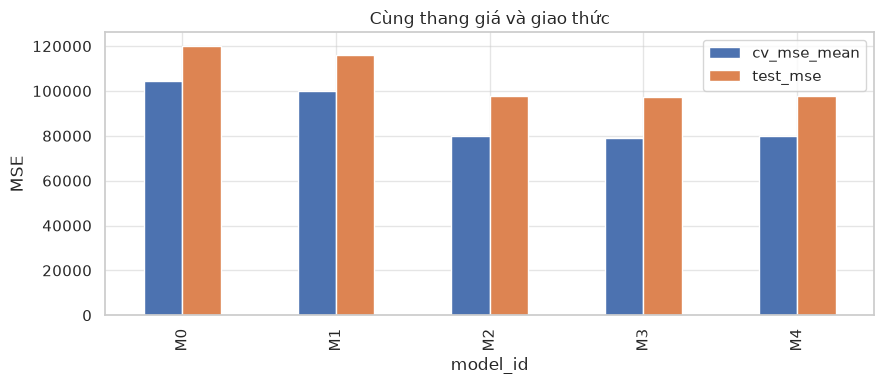

In [65]:
X_test, y_test = test[predictor_names(config)], test[config['target']]
comparison_rows, prediction_frames = [], []
for row in selected_cv.itertuples():
    predicted = models[row.model_id].predict(X_test)
    mse = mean_squared_error(y_test, predicted)
    comparison_rows.append({'model_id': row.model_id, 'variant': row.variant,
        'protocol_id': config['protocol_id'], 'n_train': len(train), 'n_test': len(test),
        'cv_mse_mean': row.cv_mse_mean, 'cv_rmse_mean': row.cv_rmse_mean,
        'cv_mae_mean': row.cv_mae_mean, 'cv_r2_mean': row.cv_r2_mean,
        'test_mse': mse, 'test_rmse': np.sqrt(mse),
        'test_mae': mean_absolute_error(y_test, predicted), 'test_r2': r2_score(y_test, predicted),
        'selected_winning_model': row.model_id == winner_id})
    part = test.copy()
    part['actual'], part['predicted'] = y_test.to_numpy(), predicted
    part['residual'] = part.actual - part.predicted
    part['model_id'], part['split'], part['protocol_id'] = row.model_id, 'test', config['protocol_id']
    prediction_frames.append(part)
comparison = pd.DataFrame(comparison_rows)
predictions = pd.concat(prediction_frames, ignore_index=True)
assert len(predictions) == 5 * 10342
assert not predictions.duplicated(['model_id', 'source_file', 'source_row']).any()
display(comparison[['model_id', 'variant', 'cv_mse_mean', 'test_mse', 'test_rmse', 'test_mae',
                    'test_r2', 'selected_winning_model']])
save_table(comparison, 'model_comparison.csv')
save_table(predictions, 'test_predictions.csv')
fig, ax = plt.subplots(figsize=(9, 4))
comparison.set_index('model_id')[['cv_mse_mean', 'test_mse']].plot.bar(ax=ax)
ax.set(title='Cùng thang giá và giao thức', ylabel='MSE')
plt.tight_layout(); plt.show()

## 5. Phần dư, lỗi theo nhóm và kết luận — Huy, Hàn kiểm tra

Residual = actual−predicted: dương nghĩa là dự đoán thấp. Phân tích mô hình đã khóa bằng CV.
Giữ dự đoán âm để phản ánh giới hạn; không clip sau khi nhìn test. Báo lỗi kèm số mẫu từng nhóm.
Các case sai số lớn được truy lại file/dòng, không gọi là gian lận hoặc giá sai.

,grouping,city,n,rmse,mae,mean_residual,negative_predictions,room_type,day_type
0,city,amsterdam,395,265.0974,173.3768,-12.4205,0,NaN,NaN
1,city,athens,1040,580.4380,87.2988,23.3738,70,NaN,NaN
2,city,barcelona,563,306.5031,104.0113,-12.5253,0,NaN,NaN
3,city,berlin,511,292.6332,102.1481,16.0201,2,NaN,NaN
4,city,budapest,780,159.7910,76.1553,-0.7770,28,NaN,NaN
5,city,lisbon,1154,101.2393,71.7593,0.7013,26,NaN,NaN
6,city,london,2020,253.0558,123.7189,-17.9117,0,NaN,NaN
7,city,paris,1323,502.1352,148.6173,11.9242,0,NaN,NaN
8,city,rome,1841,124.2138,78.8640,-0.6450,33,NaN,NaN
9,city,vienna,715,98.3406,71.5729,-10.2406,8,NaN,NaN


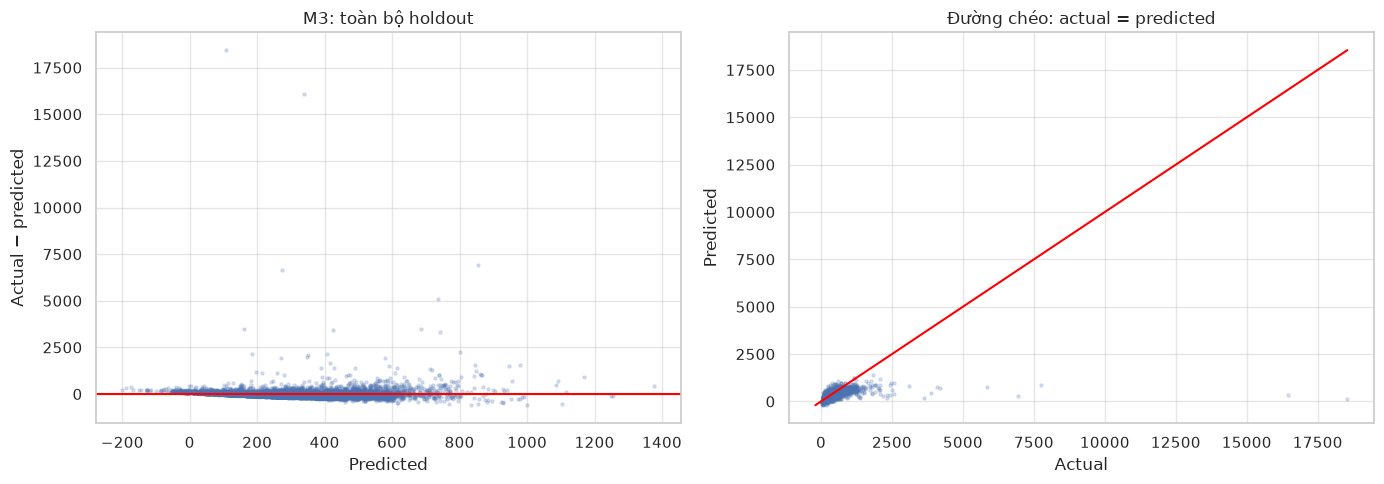

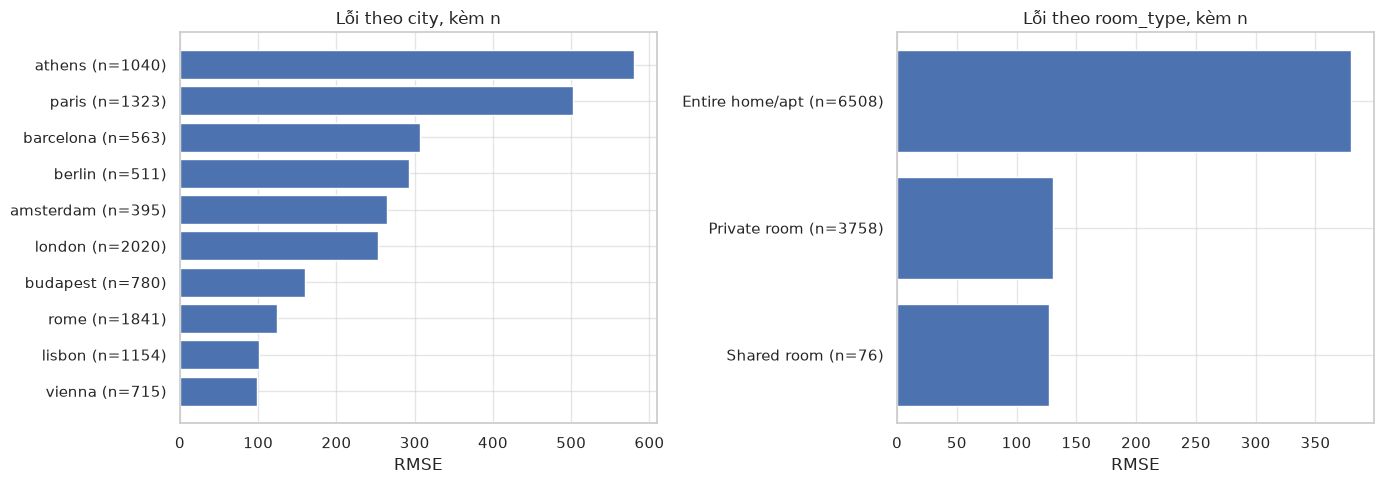

In [66]:
winner = predictions.loc[predictions.model_id.eq(winner_id)].copy()
assert len(winner) == 10342
pd.testing.assert_frame_equal(winner[config['trace_keys']].reset_index(drop=True), test[config['trace_keys']])
np.testing.assert_allclose(winner.actual, test.realSum, rtol=0, atol=0)
winner['abs_residual'] = winner.residual.abs()
winner['squared_residual'] = winner.residual ** 2
def group_error(frame):
    return {'n': len(frame), 'rmse': np.sqrt(frame.squared_residual.mean()),
            'mae': frame.abs_residual.mean(), 'mean_residual': frame.residual.mean(),
            'negative_predictions': int(frame.predicted.lt(0).sum())}
error_rows = []
for cols in [['city'], ['room_type'], ['day_type'], ['city', 'room_type']]:
    for key, part in winner.groupby(cols, observed=True):
        keys = key if isinstance(key, tuple) else (key,)
        error_rows.append({'grouping': '+'.join(cols), **dict(zip(cols, keys)), **group_error(part)})
group_errors = pd.DataFrame(error_rows)
display(group_errors.loc[group_errors.grouping.isin(['city', 'room_type', 'day_type'])])
save_table(group_errors, 'residual_group_errors.csv')
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(winner.predicted, winner.residual, s=5, alpha=.2)
axes[0].axhline(0, color='red')
axes[0].set(xlabel='Predicted', ylabel='Actual − predicted', title=f'{winner_id}: toàn bộ holdout')
axes[1].scatter(winner.actual, winner.predicted, s=5, alpha=.2)
low, high = min(winner.actual.min(), winner.predicted.min()), max(winner.actual.max(), winner.predicted.max())
axes[1].plot([low, high], [low, high], color='red')
axes[1].set(xlabel='Actual', ylabel='Predicted', title='Đường chéo: actual = predicted')
plt.tight_layout(); plt.show()
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, col in zip(axes, ['city', 'room_type']):
    part = group_errors.loc[group_errors.grouping.eq(col)].sort_values('rmse')
    ax.barh([f'{r[col]} (n={int(r["n"])})' for _,r in part.iterrows()], part.rmse)
    ax.set(xlabel='RMSE', title=f'Lỗi theo {col}, kèm n')
plt.tight_layout(); plt.show()

,source_file,source_row,city,room_type,person_capacity,bedrooms,dist,actual,predicted,residual
31719,athens_weekdays.csv,1510,athens,Entire home/apt,2.0000,1,1.1965,"18,545.4503",106.8821,"18,438.5682"
37936,paris_weekdays.csv,2348,paris,Entire home/apt,2.0000,1,4.6024,"16,445.6147",337.5500,"16,108.0647"
37241,london_weekends.csv,4109,london,Entire home/apt,6.0000,3,1.7091,"7,759.3546",853.9734,"6,905.3812"
32689,barcelona_weekdays.csv,1065,barcelona,Entire home/apt,2.0000,1,4.5758,"6,943.7010",273.9734,"6,669.7276"
33501,berlin_weekends.csv,1022,berlin,Entire home/apt,6.0000,3,1.1924,"5,856.0811",736.7028,"5,119.3783"
38800,paris_weekends.csv,3507,paris,Entire home/apt,4.0000,3,3.8694,"4,188.4146",684.8062,"3,503.6084"
33912,budapest_weekdays.csv,1938,budapest,Entire home/apt,3.0000,1,2.0182,"3,630.6810",160.1534,"3,470.5276"
36710,london_weekends.csv,1503,london,Entire home/apt,2.0000,2,7.6790,"3,866.0364",425.9213,"3,440.1151"
37684,paris_weekdays.csv,1041,paris,Entire home/apt,6.0000,3,3.9221,"4,068.6457",741.8529,"3,326.7929"
38145,paris_weekends.csv,256,paris,Entire home/apt,6.0000,3,1.3350,"3,081.8343",802.0882,"2,279.7461"


,Unnamed: 0,realSum,room_type,room_shared,room_private,person_capacity,host_is_superhost,multi,biz,cleanliness_rating,guest_satisfaction_overall,bedrooms,dist,metro_dist,attr_index,attr_index_norm,rest_index,rest_index_norm,lng,lat
1510,1510,"18,545.4503",Entire home/apt,False,False,2.0000,True,0,1,10.0000,100.0000,1,1.1965,0.3811,134.9044,5.0865,275.5737,20.6918,23.7320,37.9860


104 dòng lỗi bình phương lớn nhất (1.01% mẫu) chiếm 86.08% SSE.
Số dự đoán âm: 167
Mean residual: -0.790468059199979 | Median AE: 70.91507643040214 | P90 AE: 186.45871143872773


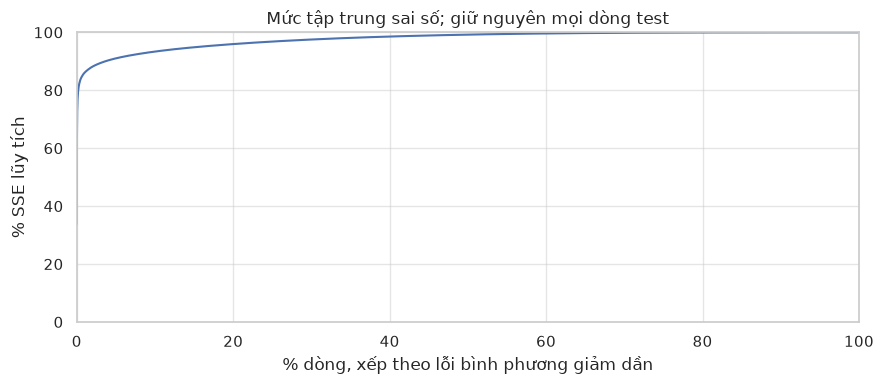

In [67]:
ordered = winner.sort_values('squared_residual', ascending=False)
top_n = int(np.ceil(len(winner)*.01))
top_share = ordered.head(top_n).squared_residual.sum()/winner.squared_residual.sum()
cases = ordered.head(10)[['source_file', 'source_row', 'city', 'room_type', 'person_capacity',
                          'bedrooms', 'dist', 'actual', 'predicted', 'residual']]
display(cases)
save_table(cases, 'residual_cases.csv')
case = cases.iloc[0]
raw_case = pd.read_csv(ROOT / 'data/raw' / case.source_file)
raw_case = raw_case.loc[raw_case['Unnamed: 0'].eq(case.source_row)]
assert len(raw_case) == 1
np.testing.assert_allclose(raw_case.realSum.iloc[0], case.actual, rtol=0, atol=0)
display(raw_case)
print(f'{top_n} dòng lỗi bình phương lớn nhất ({top_n/len(winner):.2%} mẫu) chiếm {top_share:.2%} SSE.')
print('Số dự đoán âm:', winner.predicted.lt(0).sum())
print('Mean residual:', winner.residual.mean(), '| Median AE:', winner.abs_residual.median(),
      '| P90 AE:', winner.abs_residual.quantile(.9))
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(np.arange(1, len(ordered)+1)/len(ordered)*100,
        ordered.squared_residual.cumsum()/ordered.squared_residual.sum()*100)
ax.set(xlabel='% dòng, xếp theo lỗi bình phương giảm dần', ylabel='% SSE lũy tích',
       title='Mức tập trung sai số; giữ nguyên mọi dòng test', xlim=(0,100), ylim=(0,100))
plt.tight_layout(); plt.show()

In [68]:
selected = comparison.loc[comparison.model_id.eq(winner_id)].iloc[0]
baseline = comparison.loc[comparison.model_id.eq('M0')].iloc[0]
improvement = (baseline.test_mse-selected.test_mse)/baseline.test_mse*100
display(Markdown(f"""### 5.1. Kết luận từ kết quả thực nghiệm

Phân tích **{len(df):,} quan sát** cho thấy giá lệch phải và mẫu khác cơ cấu giữa các nhóm.
Mean/median/n, Pearson theo city và ANOVA giúp mô tả những liên hệ này, với giới hạn giả định rõ ràng.
**{winner_id}, đa thức bậc 3**, được chọn bằng CV MSE, không chọn theo điểm test.
Trên **{len(test):,} holdout**, RMSE **{selected.test_rmse:.2f}**, MAE **{selected.test_mae:.2f}**,
R² **{selected.test_r2:.4f}**; MSE giảm **{improvement:.2f}%** so với baseline M0 trên cùng test.
Mức giải thích biến thiên còn thấp và có **{int(winner.predicted.lt(0).sum())} dự đoán âm**.
**{top_n} dòng lỗi lớn nhất** chiếm **{top_share:.2%} SSE**, cho thấy ít quan sát có thể chi phối MSE.
Thiếu metadata kỳ giá/listing ID và khả năng lặp tọa độ giữa train/test hạn chế khả năng khái quát.
Kết quả chưa chứng minh nhân quả, gian lận hoặc chất lượng định giá ở một thị trường khác.
"""))

### 5.1. Kết luận từ kết quả thực nghiệm

Phân tích **51,707 quan sát** cho thấy giá lệch phải và mẫu khác cơ cấu giữa các nhóm.
Mean/median/n, Pearson theo city và ANOVA giúp mô tả những liên hệ này, với giới hạn giả định rõ ràng.
**M3, đa thức bậc 3**, được chọn bằng CV MSE, không chọn theo điểm test.
Trên **10,342 holdout**, RMSE **311.70**, MAE **102.02**,
R² **0.1912**; MSE giảm **19.12%** so với baseline M0 trên cùng test.
Mức giải thích biến thiên còn thấp và có **167 dự đoán âm**.
**104 dòng lỗi lớn nhất** chiếm **86.08% SSE**, cho thấy ít quan sát có thể chi phối MSE.
Thiếu metadata kỳ giá/listing ID và khả năng lặp tọa độ giữa train/test hạn chế khả năng khái quát.
Kết quả chưa chứng minh nhân quả, gian lận hoặc chất lượng định giá ở một thị trường khác.


## 6. Phân công, kiểm tra và cách trình bày

| Phần | Chủ trì | Khi thầy hỏi code cần giải thích |
|---|---|---|
| Dữ liệu/từ điển/IQR (T02–T04) | Hàn, Huy kiểm | Schema, metadata chưa rõ, khóa truy vết, giữ ngoại lệ |
| EDA/Pearson/ANOVA (T05–T06) | Huy, Hàn kiểm | groupby/pivot, n và nhóm trống, r/F/p, giới hạn |
| Giao thức (T07) | Cả hai | Split/fold cố định, allowlist, không leakage |
| M0–M2 (T08) | Hàn, Huy kiểm | Baseline, hệ số, scaler và dummy |
| M3–M4 (T09) | Huy, Hàn kiểm | Đa thức ba biến, bậc/alpha, chọn CV và refit |
| Holdout (T10) | Cả hai | Bốn metric, cùng test, CV khác test |
| Phần dư (T11) | Huy, Hàn kiểm | Dấu phần dư, lỗi nhóm, SSE và case truy nguồn |
| Kết luận/slide (T13/T15) | Huy, Hàn đọc chéo | Kết quả thật và giới hạn, khớp báo cáo |
| Notebook cuối/kiểm gói (T16–T17) | Cả hai | Restart & Run All; kiểm trên cả hai máy |

Notebook này thay cho việc trình bày lần lượt nhiều file. Không tự đánh dấu đã diễn tập,
đã kiểm máy Hàn hoặc đã đủ thông tin nhóm/LMS. Khi nói: giới thiệu câu hỏi và dữ liệu,
chọn vài bảng/hình trả lời câu hỏi, giải thích CV→test và điểm sai lớn; mở code ở đúng phần khi được hỏi.

Code được gom từ `src/experiment.py` và phần bảng EDA của `src/b_tasks.py`, cùng quy trình
dữ liệu/M0–M2/đánh giá/phần dư đã có trong các notebook 01–05. Dictionary lấy từ bản T03 đã review;
các kết quả mô hình và hình trên đây được tính lại trong kernel này, không lấy điểm từ văn bản.
Tài liệu quy tắc nhóm: `Skill/SKILL.md`; kế hoạch: `Skill/KE_HOACH_DO_AN_IE313.md`.

In [70]:
# Bằng chứng chạy đầy đủ: kiểm metric với snapshot T10 nếu file bàn giao có sẵn.
reference_path = ROOT / 'outputs/tables/model_comparison_cv_vs_test.csv'
if reference_path.exists():
    reference = pd.read_csv(reference_path).set_index('model_id').sort_index()
    metric_columns = ['cv_mse_mean', 'cv_rmse_mean', 'cv_mae_mean', 'cv_r2_mean',
                      'test_mse', 'test_rmse', 'test_mae', 'test_r2']
    np.testing.assert_allclose(comparison.set_index('model_id').sort_index()[metric_columns],
                               reference[metric_columns], rtol=1e-8, atol=1e-6)
assert int(winner.predicted.lt(0).sum()) == 167
assert top_n == 104
assert models['M3'].named_steps['preprocess'].transform(X_train.iloc[:1]).shape[1] == 35
evidence = {'n_raw_files': len(raw_files), 'data_shape': list(df.shape), 'n_train': len(train),
            'n_test': len(test), 'n_cv_configurations': len(cv_summary), 'n_fold_records': len(cv_folds),
            'prediction_rows': len(predictions), 'selected_by_cv': winner_id,
            'negative_predictions': int(winner.predicted.lt(0).sum()), 'top_1_percent_rows': top_n,
            'top_1_percent_share_sse': float(top_share), 'protocol_id': config['protocol_id'],
            'data_sha256': hash_now, 'raw_csv_sha256': {p.name: hashlib.sha256(p.read_bytes()).hexdigest() for p in raw_files},
            'all_assertions_passed': True}
(FINAL_DIR / 'run_evidence.json').write_text(json.dumps(evidence, ensure_ascii=False, indent=2), encoding='utf-8')
print('ĐÃ CHẠY ĐẾN CUỐI: kiểm dữ liệu/split/folds/metric/truy vết đạt. Kết quả:', FINAL_DIR)

ĐÃ CHẠY ĐẾN CUỐI: kiểm dữ liệu/split/folds/metric/truy vết đạt. Kết quả: P:\CITD\HK3\Phân tích và trực quan dữ liệu\Đồ án môn học\Source\outputs\final_notebook
